# 02 — Amostras, escolha do limiar e classificação mensal

**Projeto:** Área queimada no Parque Nacional da Chapada das Mesas (MA), estação seca de 2024
**Bootcamp:** Space Tech Bootcamp 2026 — Future Tech Leaders Brasil

### O que este notebook faz
1. Refaz as composições mensais do notebook 01 e calcula o **dNBR de cada mês**.
2. Você **desenha amostras** no mapa: polígonos sobre áreas **queimadas** e sobre áreas **não queimadas**.
3. Com essas amostras, escolhemos o **limiar** de dNBR que melhor separa as duas classes.
4. Classificamos cada pixel pelo **mês em que queimou**, sem contar a mesma cicatriz duas vezes.
5. Calculamos a **área queimada (ha) por mês e acumulada**, com tabela, gráfico e mapa.

> **Tempo estimado:** 1h30 a 2h, a maior parte desenhando as amostras (Etapa 4). Execute as células **em ordem**, com Shift + Enter, e leia o texto antes de cada uma.

**Resultados deste notebook são preliminares:** a validação com o MapBiomas Fogo vem no notebook 03.

## Etapa 0 — Conexão (igual ao notebook 01)

In [1]:
!pip install -q geemap

In [2]:
import ee

PROJETO = 'lirun-94f92'
ee.Authenticate()
ee.Initialize(project=PROJETO)
print('Earth Engine conectado ao projeto:', PROJETO)

Earth Engine conectado ao projeto: lirun-94f92


In [3]:
try:
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass

import geemap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os, json, urllib.request
from IPython.display import Image, display

os.makedirs('resultados/figuras', exist_ok=True)
os.makedirs('resultados/tabelas', exist_ok=True)

## Etapa 1 — Parâmetros

- **COMPOSICAO:** como juntar as imagens de cada mês.
  - `'mediana'`: para cada pixel, o valor do meio entre as imagens do mês. Foi o que usamos no notebook 01. É robusta a ruído, mas uma queimada no **fim do mês** pode só aparecer no mês seguinte.
  - `'minimo'`: para cada pixel, a imagem do mês com o **menor NBR**, a mesma ideia do MapBiomas Fogo. Pega a queimada no mês certo, mas é mais sensível a restos de nuvem e sombra.
  - Comece com `'mediana'`. Se sobrar tempo, rode tudo de novo com `'minimo'` e compare os totais. Essa comparação é um bom ponto para a apresentação.
- **MIN_PIXELS:** manchas classificadas como queimadas com menos pixels conectados que esse valor são descartadas como ruído. Com 3 pixels de 20 m, o mínimo é 0,12 ha.

In [4]:
ANO = 2024
MES_REFERENCIA = 5             # maio: referência pré-fogo
MESES_ANALISE = [6, 7, 8, 9, 10]
LIMIAR_NUVEM = 0.60
COMPOSICAO = 'mediana'         # 'mediana' ou 'minimo'
MIN_PIXELS = 3                 # remove manchas menores que isso (ruído)
ESCALA = 20                    # metros (resolução das bandas B8A e B12)

NOMES_MES = {5: 'mai', 6: 'jun', 7: 'jul', 8: 'ago', 9: 'set', 10: 'out'}

## Etapa 2 — Parque, imagens e composições mensais

In [5]:
wdpa = ee.FeatureCollection('WCMC/WDPA/current/polygons')
parque = (wdpa.filter(ee.Filter.eq('ISO3', 'BRA'))
              .filter(ee.Filter.stringContains('NAME', 'Chapada Das Mesas')))
area = parque.geometry()
print('Polígonos do parque:', parque.size().getInfo(),
      '| área (ha):', round(area.area(maxError=10).divide(1e4).getInfo()))

s2 = ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
csplus = ee.ImageCollection('GOOGLE/CLOUD_SCORE_PLUS/V1/S2_HARMONIZED')

def preparar(img):
    img = img.updateMask(img.select('cs_cdf').gte(LIMIAR_NUVEM))
    nbr = img.normalizedDifference(['B8A', 'B12']).rename('NBR')
    return img.select(['B4', 'B8A', 'B12']).addBands(nbr).addBands(nbr.multiply(-1).rename('NBR_neg'))

colecao = (s2.filterBounds(area)
             .filterDate(ee.Date.fromYMD(ANO, MES_REFERENCIA, 1),
                         ee.Date.fromYMD(ANO, max(MESES_ANALISE), 1).advance(1, 'month'))
             .linkCollection(csplus, ['cs_cdf'])
             .map(preparar))

def composicao_mensal(mes):
    ini = ee.Date.fromYMD(ANO, mes, 1)
    do_mes = colecao.filterDate(ini, ini.advance(1, 'month'))
    if COMPOSICAO == 'minimo':
        comp = do_mes.qualityMosaic('NBR_neg')   # pixel com o menor NBR do mês
    else:
        comp = do_mes.median()
    comp = comp.select(['B4', 'B8A', 'B12'])
    nbr = comp.normalizedDifference(['B8A', 'B12']).rename('NBR')
    return comp.addBands(nbr).clip(area)

meses_todos = [MES_REFERENCIA] + MESES_ANALISE
comps = {m: composicao_mensal(m) for m in meses_todos}
print('Composição:', COMPOSICAO, '| meses:', meses_todos)

Polígonos do parque: 1 | área (ha): 160638
Composição: mediana | meses: [5, 6, 7, 8, 9, 10]


## Etapa 3 — dNBR de cada mês e dNBR máximo

Para cada mês da análise:

$$dNBR_{mês} = NBR_{mês\ anterior} - NBR_{mês}$$

Por exemplo, o dNBR de julho mede o que mudou **de junho para julho**.

Depois juntamos os 5 meses num só número por pixel: o **dNBR máximo**, ou seja, a maior queda de NBR que aquele pixel teve em qualquer mês.
- Pixel que queimou: no mês da queima o dNBR é alto, então o máximo é alto.
- Pixel que não queimou: só tem as quedas pequenas da seca, então o máximo é baixo.

É sobre o **dNBR máximo** que vamos escolher o limiar.

In [6]:
dnbr = {}
for m in MESES_ANALISE:
    dnbr[m] = comps[m - 1].select('NBR').subtract(comps[m].select('NBR')).rename('dNBR')

dnbr_max = ee.ImageCollection([dnbr[m] for m in MESES_ANALISE]).max().rename('dNBR_max')
print('dNBR calculado para os meses:', MESES_ANALISE)

dNBR calculado para os meses: [6, 7, 8, 9, 10]


## Etapa 4 — Desenhar as amostras ✏️

Esta é a etapa mais importante e a única manual. Você vai **desenhar polígonos** em dois mapas:

- **Mapa A — QUEIMADO:** áreas que você tem certeza de que queimaram.
- **Mapa B — NÃO QUEIMADO:** áreas que você tem certeza de que **não** queimaram.

### Como reconhecer
Use as camadas de **falsa-cor (B12, B8A, B4)** de cada mês e **ligue e desligue** os meses no ícone de camadas, no canto superior direito.
- **Queimado:** uma área que estava **verde ou amarelada** e, num mês seguinte, ficou **escura** (preta, marrom ou arroxeada), com bordas nítidas.
- **Não queimado:** áreas que ficam verdes ou amareladas em **todos** os meses, sem escurecer. Inclua vegetação diferente: matas ao longo dos rios (verde forte), cerrado aberto (amarelado) e chapadas.
- A camada **dNBR máximo** ajuda a achar candidatas (manchas vermelho-escuras), mas **confirme sempre na falsa-cor**. O objetivo é justamente testar o índice com o seu olho.

### Como desenhar
1. Na barra da esquerda do mapa, clique no ícone de **polígono** (⬠) ou de **retângulo** (▭).
2. Clique no mapa para fazer os vértices; feche o polígono clicando no primeiro ponto. O retângulo é clicar e arrastar.
3. Faça **de 10 a 15 polígonos em cada mapa**, **espalhados pelo parque inteiro**: norte, centro, leste e o fragmento sul.
4. Desenhe **dentro** das manchas, longe das bordas, e evite misturar classes num mesmo polígono.
5. Polígonos pequenos estão ótimos: algo como um quarteirão a um bairro na escala do mapa.

**Errou?** Use o ícone de **lixeira** na barra de desenho para apagar.

In [7]:
vis_falsa = {'bands': ['B12', 'B8A', 'B4'], 'min': 0, 'max': 3500}
vis_dnbr = {'min': -0.2, 'max': 0.6, 'palette': ['1a9850', 'ffffbf', 'fdae61', 'd73027', '67001f']}
contorno = ee.Image().paint(parque, 0, 2)

def mapa_base():
    m = geemap.Map(basemap='SATELLITE')
    m.centerObject(area, 10)
    for mes in meses_todos:
        m.addLayer(comps[mes], vis_falsa, f'Falsa-cor {NOMES_MES[mes]}', mes in (MES_REFERENCIA, 10))
    m.addLayer(dnbr_max, vis_dnbr, 'dNBR máximo (jun–out)', False)
    m.addLayer(contorno, {'palette': 'white'}, 'Limite do parque')
    return m

def pegar_desenhos(m):
    # Lê os polígonos desenhados (funciona em diferentes versões do geemap)
    for nome in ['user_rois', '_user_rois']:
        fc = getattr(m, nome, None)
        if fc is not None:
            return ee.FeatureCollection(fc)
    dc = getattr(m, 'draw_control', None) or getattr(m, '_draw_control', None)
    if dc is not None and getattr(dc, 'collection', None) is not None:
        return ee.FeatureCollection(dc.collection)
    feats = getattr(m, 'draw_features', None)
    if feats:
        return ee.FeatureCollection(feats)
    raise RuntimeError('Nenhum polígono encontrado. Desenhou no mapa certo?')

print('Pronto. Rode a próxima célula para abrir o Mapa A.')

Pronto. Rode a próxima célula para abrir o Mapa A.


### Mapa A — desenhe áreas QUEIMADAS 🔥

In [15]:
mapa_queimado = mapa_base()
mapa_queimado

Map(center=[-7.1524703258955125, -47.14468687103683], controls=(WidgetControl(options=['position', 'transparen…

Quando terminar de desenhar no Mapa A, rode a célula abaixo para guardar os polígonos.

In [16]:
amostras_queimado = pegar_desenhos(mapa_queimado).map(lambda f: f.set('classe', 1))
n_q = amostras_queimado.size().getInfo()
print('Polígonos QUEIMADOS guardados:', n_q)
if n_q < 8:
    print('⚠️ Poucos polígonos. O ideal são 10 a 15. Você pode voltar ao Mapa A, desenhar mais e rodar esta célula de novo.')

Polígonos QUEIMADOS guardados: 18


### Mapa B — desenhe áreas NÃO QUEIMADAS 🌿

In [10]:
mapa_nao_queimado = mapa_base()
mapa_nao_queimado

Map(center=[-7.1524703258955125, -47.14468687103683], controls=(WidgetControl(options=['position', 'transparen…

In [11]:
amostras_nao_queimado = pegar_desenhos(mapa_nao_queimado).map(lambda f: f.set('classe', 0))
n_n = amostras_nao_queimado.size().getInfo()
print('Polígonos NÃO QUEIMADOS guardados:', n_n)
if n_n < 8:
    print('⚠️ Poucos polígonos. O ideal são 10 a 15.')

# Salva as amostras (para reprodutibilidade e para o GitHub)
amostras = amostras_queimado.merge(amostras_nao_queimado)
try:
    geemap.ee_export_vector(amostras, 'resultados/tabelas/amostras_poligonos.geojson')
    print('Amostras salvas em resultados/tabelas/amostras_poligonos.geojson')
except Exception as e:
    print('Não foi possível salvar o GeoJSON (não impede continuar):', e)

Polígonos NÃO QUEIMADOS guardados: 0
⚠️ Poucos polígonos. O ideal são 10 a 15.
Não foi possível salvar o GeoJSON (não impede continuar): Element.propertyNames: Parameter 'element' is required and may not be null.


## Etapa 5 — Valores de dNBR das amostras

Sorteamos até 300 pixels dentro dos polígonos de cada classe e lemos o **dNBR máximo** de cada pixel.

**O que esperar:** os pixels queimados com valores altos; os não queimados com valores baixos; e uma **sobreposição** entre os dois grupos, que é onde mora o erro.

Empty DataFrame
Columns: [count, mean, std, min, 25%, 50%, 75%, max]
Index: []


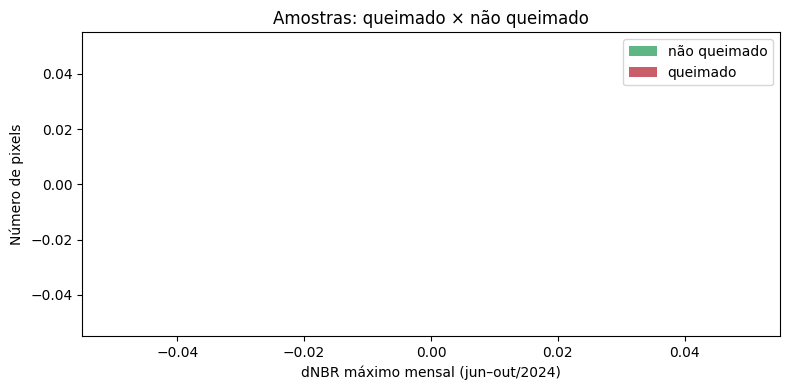

In [12]:
def amostrar(fc, classe, n=300):
    pts = dnbr_max.addBands(ee.Image.constant(classe).rename('classe')).stratifiedSample(
        numPoints=n, classBand='classe', region=fc.geometry(), scale=ESCALA,
        seed=42, geometries=False)
    return pts

tab = amostrar(amostras_queimado, 1).merge(amostrar(amostras_nao_queimado, 0))
dados = pd.DataFrame({
    'dNBR_max': tab.aggregate_array('dNBR_max').getInfo(),
    'classe': tab.aggregate_array('classe').getInfo(),
}).dropna()
dados['classe_nome'] = dados['classe'].map({1: 'queimado', 0: 'não queimado'})

print(dados.groupby('classe_nome')['dNBR_max'].describe().round(3))

fig, ax = plt.subplots(figsize=(8, 4))
bins = np.linspace(dados['dNBR_max'].min(), dados['dNBR_max'].max(), 50)
ax.hist(dados.loc[dados.classe == 0, 'dNBR_max'], bins=bins, alpha=0.7, color='#1a9850', label='não queimado')
ax.hist(dados.loc[dados.classe == 1, 'dNBR_max'], bins=bins, alpha=0.7, color='#b2182b', label='queimado')
ax.set_xlabel('dNBR máximo mensal (jun–out/2024)')
ax.set_ylabel('Número de pixels')
ax.set_title('Amostras: queimado × não queimado')
ax.legend()
plt.tight_layout()
plt.savefig('resultados/figuras/histograma_amostras.png', dpi=150)
plt.show()

## Etapa 6 — Escolha do limiar

Testamos limiares de 0,05 a 0,60. Para cada um calculamos, **nas suas amostras**:

- **Erro de omissão:** % dos pixels **queimados** que o limiar deixou de fora.
- **Erro de comissão:** % dos pixels que o limiar chamou de queimado, mas que **não queimaram**.
- **Acurácia balanceada:** média dos acertos nas duas classes.

Escolhemos o limiar com **maior acurácia balanceada**. É um critério objetivo e fácil de explicar na apresentação.

> As amostras foram usadas para **escolher** o limiar, então esses erros são otimistas. A avaliação independente vem no notebook 03, com o MapBiomas Fogo.

In [13]:
linhas = []
q = dados[dados.classe == 1]['dNBR_max'].values
n = dados[dados.classe == 0]['dNBR_max'].values
for t in np.round(np.arange(0.05, 0.605, 0.01), 2):
    vp = (q > t).sum(); fn = (q <= t).sum()     # queimados acertados / perdidos
    fp = (n > t).sum(); vn = (n <= t).sum()     # não queimados errados / acertados
    omissao = fn / len(q) * 100
    comissao = fp / (vp + fp) * 100 if (vp + fp) > 0 else np.nan
    acc_bal = ((vp / len(q)) + (vn / len(n))) / 2 * 100
    linhas.append({'limiar': t, 'omissão (%)': round(omissao, 1),
                   'comissão (%)': round(comissao, 1), 'acurácia balanceada (%)': round(acc_bal, 1)})

limiares = pd.DataFrame(linhas)
melhor = limiares.loc[limiares['acurácia balanceada (%)'].idxmax()]
LIMIAR = float(melhor['limiar'])
limiares.to_csv('resultados/tabelas/teste_limiares.csv', index=False)

print(f'>>> Limiar escolhido: dNBR_max > {LIMIAR:.2f}')
print(melhor.to_string())

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(limiares['limiar'], limiares['omissão (%)'], label='omissão', color='#b2182b')
ax.plot(limiares['limiar'], limiares['comissão (%)'], label='comissão', color='#2166ac')
ax.plot(limiares['limiar'], limiares['acurácia balanceada (%)'], label='acurácia balanceada', color='black')
ax.axvline(LIMIAR, linestyle='--', color='gray')
ax.set_xlabel('Limiar de dNBR'); ax.set_ylabel('%'); ax.legend()
ax.set_title(f'Escolha do limiar (escolhido: {LIMIAR:.2f})')
plt.tight_layout()
plt.savefig('resultados/figuras/escolha_limiar.png', dpi=150)
plt.show()

json.dump({'LIMIAR': LIMIAR, 'COMPOSICAO': COMPOSICAO, 'MIN_PIXELS': MIN_PIXELS,
           'n_poligonos_queimado': n_q, 'n_poligonos_nao_queimado': n_n},
          open('resultados/tabelas/parametros_escolhidos.json', 'w'), indent=2)

KeyError: nan

## Etapa 7 — Classificação mensal sem dupla contagem

Para cada pixel, perguntamos mês a mês, de junho a outubro: *"o dNBR deste mês passou do limiar?"*. O pixel recebe o **primeiro** mês em que isso acontece. Se a mesma cicatriz continuar escura nos meses seguintes, ela **não é contada de novo**.

Depois removemos manchas muito pequenas (menos de `MIN_PIXELS` pixels conectados), que costumam ser ruído.

In [ ]:
mes_queima = ee.Image(0)
for m in reversed(MESES_ANALISE):        # de trás para frente: o mês mais cedo "vence"
    mes_queima = mes_queima.where(dnbr[m].gt(LIMIAR), m)
mes_queima = mes_queima.rename('mes_queima').clip(area)

queimado = mes_queima.gt(0)
tamanho = queimado.selfMask().connectedPixelCount(maxSize=50, eightConnected=True)
mes_queima = mes_queima.updateMask(queimado.And(tamanho.gte(MIN_PIXELS)))

vis_mes = {'min': 6, 'max': 10, 'palette': ['fde725', '5ec962', '21918c', '3b528b', '440154']}

Map = geemap.Map(basemap='SATELLITE')
Map.centerObject(area, 10)
Map.addLayer(comps[10], vis_falsa, 'Falsa-cor out', False)
Map.addLayer(mes_queima, vis_mes, 'Mês da queima')
Map.addLayer(contorno, {'palette': 'white'}, 'Limite do parque')
Map.add_legend(title='Mês da queima', legend_dict={
    'jun': 'fde725', 'jul': '5ec962', 'ago': '21918c', 'set': '3b528b', 'out': '440154'})
Map

**Confira com o olho:** as manchas coloridas coincidem com as cicatrizes que você vê na falsa-cor? Há áreas marcadas que claramente não queimaram, como sombras de relevo, rios ou lavouras? Anote o que vir: isso vai para a discussão dos erros.

## Etapa 8 — Área queimada por mês e acumulada

Somamos a área real de cada pixel (`ee.Image.pixelArea()`, em m²) agrupada pelo mês da queima e convertemos para hectares.

In [ ]:
area_ha = ee.Image.pixelArea().divide(1e4).rename('ha')
soma = area_ha.addBands(mes_queima).reduceRegion(
    reducer=ee.Reducer.sum().group(groupField=1, groupName='mes'),
    geometry=area, scale=ESCALA, maxPixels=1e13, tileScale=4)

grupos = soma.get('groups').getInfo()
por_mes = {int(g['mes']): g['sum'] for g in grupos}
area_parque = area.area(maxError=10).divide(1e4).getInfo()

serie = pd.DataFrame({'mês': [NOMES_MES[m] for m in MESES_ANALISE],
                      'área queimada no mês (ha)': [por_mes.get(m, 0.0) for m in MESES_ANALISE]})
serie['área acumulada (ha)'] = serie['área queimada no mês (ha)'].cumsum()
serie['acumulada (% do parque)'] = serie['área acumulada (ha)'] / area_parque * 100
serie = serie.round(1)
serie.to_csv(f'resultados/tabelas/serie_area_queimada_{COMPOSICAO}.csv', index=False)
serie

In [ ]:
fig, ax1 = plt.subplots(figsize=(8, 4.5))
ax1.bar(serie['mês'], serie['área queimada no mês (ha)'], color='#d73027', label='queimada no mês')
ax1.set_ylabel('Área queimada no mês (ha)')
ax2 = ax1.twinx()
ax2.plot(serie['mês'], serie['área acumulada (ha)'], color='black', marker='o', label='acumulada')
ax2.set_ylabel('Área acumulada (ha)')
ax2.set_ylim(bottom=0)
ax1.set_title(f'Área queimada no PN Chapada das Mesas — 2024 (limiar {LIMIAR:.2f}, {COMPOSICAO})')
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc='upper left')
plt.tight_layout()
plt.savefig(f'resultados/figuras/serie_area_queimada_{COMPOSICAO}.png', dpi=150)
plt.show()

## Etapa 9 — Figura do mapa para a apresentação

In [ ]:
# Fundo cinza claro dentro do parque + pixels coloridos pelo mês da queima + contorno
img =(ee.Image.constant(0).visualize(palette=['f0f0f0']).clip(area)
       .blend(mes_queima.visualize(**vis_mes))
       .blend(contorno.visualize(palette=['black'])))
url = img.getThumbURL({'region': area.bounds(), 'dimensions': 1000, 'format': 'png'})
caminho = f'resultados/figuras/mapa_mes_queima_{COMPOSICAO}.png'
urllib.request.urlretrieve(url, caminho)
print('Salvo:', caminho)
print('Legenda: amarelo = jun | verde = jul | verde-azulado = ago | azul = set | roxo = out')
display(Image(filename=caminho, width=600))

## Checklist: o que me mandar

1. Quantos polígonos você desenhou em cada classe.
2. A tabela de estatísticas e o **histograma das amostras** (Etapa 5).
3. O **limiar escolhido** e o gráfico de escolha (Etapa 6).
4. Um print do **mapa do mês da queima** (Etapa 7) e o que você achou na conferência visual.
5. A **tabela da série** e o gráfico (Etapa 8).

Baixe a pasta `resultados` (figuras e tabelas) e o notebook executado (**Arquivo → Fazer download → .ipynb**) para subir no GitHub.

**Próximo:** notebook 03, com a validação com o MapBiomas Fogo 2024 (erros de omissão e comissão) e as figuras finais.

---
*Problemas comuns*
- **"Nenhum polígono encontrado":** confira se desenhou no mapa certo (A ou B) e se fechou o polígono. Depois rode de novo a célula que guarda os polígonos.
- **A barra de desenho não aparece:** rode de novo a célula do `enable_custom_widget_manager` (Etapa 0) e depois a do mapa.
- **`Computation timed out` na Etapa 8:** troque `ESCALA = 20` por `ESCALA = 30` na Etapa 1 e rode de novo a partir dali.